* **Problema:** Diagnóstico de fallas en rodamientos industriales mediante señales de vibración.
* **Dataset:** Repositorio de la *Case Western Reserve University* (CWRU).
* **Clases (Salida):** 4 categorías de clasificación (Normal, Pista Interna, Elemento Rodante y Pista Externa).
* **Diámetro de falla:** Estandarizado exclusivamente en **0.007 pulgadas**.
* **Posición de pista externa:** Fijada en **Centered @6:00** (zona de carga).
* **Cargas operativas:** Inclusión de los **4 niveles de carga** (0, 1, 2 y 3 HP) para todas las clases.
* **Segmentación de datos:** Corte de señales en **ventanas de 2048 muestras con un 50% de solapamiento**.
* **Arquitecturas de RNA:** Comparación entre **MLP con Backpropagation** y **Red Convolucional (CNN)**.



In [53]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import urllib.request
import os
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout

print("Librerías importadas correctamente. Versión de TensorFlow:", tf.__version__)

Librerías importadas correctamente. Versión de TensorFlow: 2.21.0


In [54]:
from sklearn.preprocessing import StandardScaler

# Inicializamos el escalador
scaler = StandardScaler()

# Ajustamos con Train y transformamos Train, Val y Test
X_train_norm = scaler.fit_transform(X_train)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test)

print("Datos normalizados correctamente.")

Datos normalizados correctamente.


In [55]:


# Mapeo de URLs oficiales de la CWRU para el diámetro 0.007" y las 4 cargas (0, 1, 2, 3 HP)
datasets_config = {
    'Normal': {
        '0HP': 'https://engineering.case.edu/sites/default/files/97.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/98.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/99.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/100.mat'
    },
    'Pista_Interna': {
        '0HP': 'https://engineering.case.edu/sites/default/files/105.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/106.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/107.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/108.mat'
    },
    'Elemento_Rodante': {
        '0HP': 'https://engineering.case.edu/sites/default/files/118.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/119.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/120.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/121.mat'
    },
    'Pista_Externa_6_00': {  # Tomamos la posición @6:00 como referencia principal para la clase de pista externa
        '0HP': 'https://engineering.case.edu/sites/default/files/130.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/131.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/132.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/133.mat'
    }
}

def descargar_y_cargar_mat(url, nombre_local):
    if not os.path.exists(nombre_local):
        print(f"Descargando {nombre_local}...")
        urllib.request.urlretrieve(url, nombre_local)

    mat_data = scipy.io.loadmat(nombre_local)
    # Extraer la clave del acelerador del extremo motor (DE_time)
    clave_de = [k for k in mat_data.keys() if 'DE_time' in k][0]
    return mat_data[clave_de].flatten()

# Diccionario donde guardaremos todas las señales crudas organizadas
seniales_crudas_dataset = {}

for clase, cargas in datasets_config.items():
    seniales_crudas_dataset[clase] = {}
    for carga, url in cargas.items():
        nombre_archivo = f"{clase}_{carga}.mat"
        seniales_crudas_dataset[clase][carga] = descargar_y_cargar_mat(url, nombre_archivo)
        print(f"Cargado -> Clase: {clase} | Carga: {carga} | Muestras: {len(seniales_crudas_dataset[clase][carga])}")

Cargado -> Clase: Normal | Carga: 0HP | Muestras: 243938
Cargado -> Clase: Normal | Carga: 1HP | Muestras: 483903
Cargado -> Clase: Normal | Carga: 2HP | Muestras: 483903
Cargado -> Clase: Normal | Carga: 3HP | Muestras: 485643
Cargado -> Clase: Pista_Interna | Carga: 0HP | Muestras: 121265
Cargado -> Clase: Pista_Interna | Carga: 1HP | Muestras: 121991
Cargado -> Clase: Pista_Interna | Carga: 2HP | Muestras: 122136
Cargado -> Clase: Pista_Interna | Carga: 3HP | Muestras: 122917
Cargado -> Clase: Elemento_Rodante | Carga: 0HP | Muestras: 122571
Cargado -> Clase: Elemento_Rodante | Carga: 1HP | Muestras: 121410
Cargado -> Clase: Elemento_Rodante | Carga: 2HP | Muestras: 121556
Cargado -> Clase: Elemento_Rodante | Carga: 3HP | Muestras: 121556
Cargado -> Clase: Pista_Externa_6_00 | Carga: 0HP | Muestras: 121991
Cargado -> Clase: Pista_Externa_6_00 | Carga: 1HP | Muestras: 122426
Cargado -> Clase: Pista_Externa_6_00 | Carga: 2HP | Muestras: 121410
Cargado -> Clase: Pista_Externa_6_00 | Ca

In [56]:
def segmentar_y_etiquetar(seniales_dict, tamano_ventana=2048, solapamiento=0.5):
    paso = int(tamano_ventana * (1 - solapamiento))
    X = []
    y = []

    # Mapeo de clases a valores numéricos para la red
    clases_mapeo = {
        'Normal': 0,
        'Pista_Interna': 1,
        'Elemento_Rodante': 2,
        'Pista_Externa_6_00': 3
    }

    for clase, cargas in seniales_dict.items():
        etiqueta = clases_mapeo[clase]
        for carga, senial in cargas.items():
            # Recorrer la señal y extraer ventanas
            for i in range(0, len(senial) - tamano_ventana + 1, paso):
                ventana = senial[i:i + tamano_ventana]
                X.append(ventana)
                y.append(etiqueta)

    return np.array(X), np.array(y)

# Ejecutamos la función con nuestro diccionario de señales crudas
X_global, y_global = segmentar_y_etiquetar(seniales_crudas_dataset)

print(f"Dimensiones de X_global (ventanas de datos): {X_global.shape}")
print(f"Dimensiones de y_global (etiquetas): {y_global.shape}")

Dimensiones de X_global (ventanas de datos): (3064, 2048)
Dimensiones de y_global (etiquetas): (3064,)


In [57]:
# 1. Ejecutamos la segmentación con el diccionario de señales crudas
X_global, y_global = segmentar_y_etiquetar(seniales_crudas_dataset)

print(f"Dimensiones de X_global (ventanas de datos): {X_global.shape}")
print(f"Dimensiones de y_global (etiquetas): {y_global.shape}")

# 2. Dividimos los datos asegurando al menos un 20% para el conjunto de prueba (Test)[cite: 3, 30]
from sklearn.model_selection import train_test_split

# Primero separamos Train+Val (80%) y Test (20%) de forma estratificada
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_global, y_global, test_size=0.20, random_state=42, stratify=y_global
)

# Del 80% restante, separamos un porcentaje para Validación (ej. 20% para validación, 60% para entrenamiento neto)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=42, stratify=y_train_val
)

print("\n--- Distribución de los Conjuntos ---")
print(f"Entrenamiento (Train): {X_train.shape[0]} muestras")
print(f"Validación (Val):      {X_val.shape[0]} muestras")
print(f"Prueba (Test):         {X_test.shape[0]} muestras")

Dimensiones de X_global (ventanas de datos): (3064, 2048)
Dimensiones de y_global (etiquetas): (3064,)

--- Distribución de los Conjuntos ---
Entrenamiento (Train): 1960 muestras
Validación (Val):      491 muestras
Prueba (Test):         613 muestras


In [58]:
# Inicializamos el escalador
scaler = StandardScaler()

# Ajustamos con Train y transformamos Train, Val y Test
X_train_norm = scaler.fit_transform(X_train)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test)

print("Datos normalizados correctamente.")

Datos normalizados correctamente.


Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5622 - loss: 1.3252 - val_accuracy: 0.7332 - val_loss: 0.8248
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8051 - loss: 0.6527 - val_accuracy: 0.8024 - val_loss: 0.5181
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8862 - loss: 0.3736 - val_accuracy: 0.8452 - val_loss: 0.4244
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9276 - loss: 0.2353 - val_accuracy: 0.8411 - val_loss: 0.4028
Epoch 5/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9434 - loss: 0.1964 - val_accuracy: 0.8676 - val_loss: 0.3755
Epoch 6/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9510 - loss: 0.1698 - val_accuracy: 0.8737 - val_loss: 0.3591
Epoch 7/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9638 - loss: 0.1333 - val_accuracy: 0.9002 - val_loss: 0.3638
Epoch 8/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9679 - loss: 0.1193 - val_accuracy: 0.8900 - val_loss: 0.3592
E

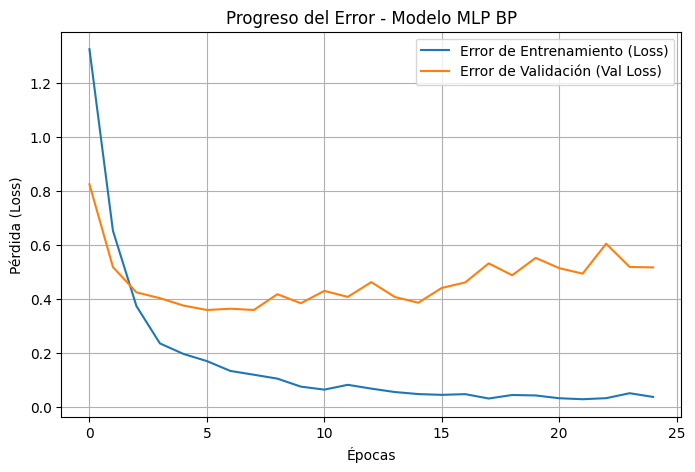

In [59]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import matplotlib.pyplot as plt

# Construcción de la arquitectura MLP
modelo_mlp = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_norm.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(4, activation='softmax')  # 4 clases de salida (Normal, Pista Interna, Elemento Rodante, Pista Externa)
])

# Compilación del modelo
modelo_mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento
historial_mlp = modelo_mlp.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=25,
    batch_size=32
)

# Gráfico del error general (Loss) exigido por la cátedra
plt.figure(figsize=(8, 5))
plt.plot(historial_mlp.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP BP')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9939 - loss: 0.0261 - val_accuracy: 0.8859 - val_loss: 0.5530
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9913 - loss: 0.0276 - val_accuracy: 0.8839 - val_loss: 0.6155
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9949 - loss: 0.0286 - val_accuracy: 0.8717 - val_loss: 0.5955
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9944 - loss: 0.0223 - val_accuracy: 0.8900 - val_loss: 0.5824


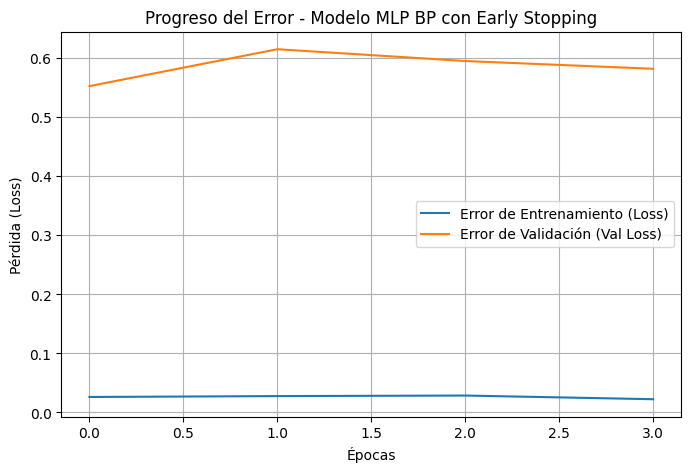

In [60]:
from tensorflow.keras.callbacks import EarlyStopping

# Configuramos el Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',          # Monitoreamos la pérdida en validación
    patience=3,                  # Número de épocas a esperar si no hay mejora
    restore_best_weights=True    # Restaura los pesos del modelo de la mejor época
)

# Re-entrenamos el modelo MLP incorporando el callback
historial_mlp = modelo_mlp.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping]
)

# Graficamos nuevamente el progreso del error
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(historial_mlp.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP BP con Early Stopping')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

La curva azul (Error de Entrenamiento): Baja continuamente hasta acercarse a cero. Esto indica que la red neuronal está memorizando a la perfección los datos con los que está entrenando.

Curva naranja (Error de Validación): Desciende al principio (alrededor de la época 4), pero a partir de ahí comienza a subir. Esto quiere decir que el modelo dejó de "aprender" patrones generales y comenzó a memorizar los datos específicos de entrenamiento. Cuando se enfrenta a datos que no conoce (el conjunto de validación), *su error empieza a empeorar en lugar de mejorar.*

Implementaremos Early Stopping (Parada Temprana).

Esta técnica monitorea el error de validación (val_loss) durante cada época y detiene automáticamente el entrenamiento en el momento exacto en que el modelo deja de mejorar, conservando los mejores pesos obtenidos hasta ese instante.

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


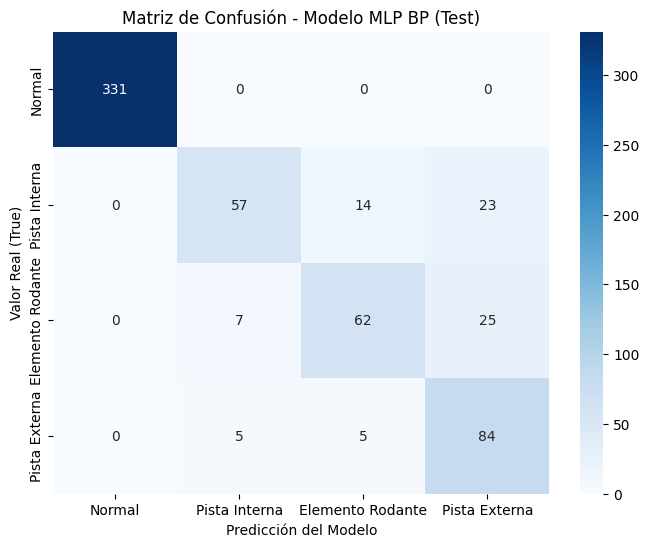

,precision,recall,f1-score,support
Normal,1.000,1.000,1.000,331.000
Pista Interna,0.826,0.606,0.699,94.000
Elemento Rodante,0.765,0.660,0.709,94.000
Pista Externa,0.636,0.894,0.743,94.000
accuracy,0.871,0.871,0.871,0.871
macro avg,0.807,0.790,0.788,613.000
weighted avg,0.882,0.871,0.870,613.000


In [61]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Predecir sobre el conjunto de prueba (Test)
y_pred_probs = modelo_mlp.predict(X_test_norm)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Calcular la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
clases_nombres = ['Normal', 'Pista Interna', 'Elemento Rodante', 'Pista Externa']

# 3. Graficar la Matriz de Confusión
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases_nombres,
            yticklabels=clases_nombres)
plt.title('Matriz de Confusión - Modelo MLP BP (Test)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (True)')
plt.show()


# 1. Obtenemos el reporte en formato de diccionario
reporte_dict = classification_report(y_test, y_pred, target_names=clases_nombres, output_dict=True)

# 2. Lo convertimos en DataFrame y redondeamos a 3 decimales
df_reporte = pd.DataFrame(reporte_dict).transpose().round(3)

# 3. Mostramos la tabla estilizada
display(df_reporte)

# ***ARQUITECTURA:RED NEURONAL CONVOLUCIONAL (CNN)***

In [62]:
# Re-formateamos los datos de entrenamiento, validación y prueba para añadir la dimensión de canal (1)
X_train_cnn = X_train_norm.reshape((X_train_norm.shape[0], X_train_norm.shape[1], 1))
X_val_cnn = X_val_norm.reshape((X_val_norm.shape[0], X_val_norm.shape[1], 1))
X_test_cnn = X_test_norm.reshape((X_test_norm.shape[0], X_test_norm.shape[1], 1))

print(f"Nueva forma de X_train para la CNN: {X_train_cnn.shape}")

Nueva forma de X_train para la CNN: (1960, 2048, 1)


In [63]:
# Re-formateamos los datos de entrenamiento, validación y prueba para añadir la dimensión de canal (1)
X_train_cnn = X_train_norm.reshape((X_train_norm.shape[0], X_train_norm.shape[1], 1))
X_val_cnn = X_val_norm.reshape((X_val_norm.shape[0], X_val_norm.shape[1], 1))
X_test_cnn = X_test_norm.reshape((X_test_norm.shape[0], X_test_norm.shape[1], 1))

print(f"Nueva forma de X_train para la CNN: {X_train_cnn.shape}")

Nueva forma de X_train para la CNN: (1960, 2048, 1)


In [64]:
# Re-formateamos los datos de entrenamiento, validación y prueba para añadir la dimensión de canal (1)
X_train_cnn = X_train_norm.reshape((X_train_norm.shape[0], X_train_norm.shape[1], 1))
X_val_cnn = X_val_norm.reshape((X_val_norm.shape[0], X_val_norm.shape[1], 1))
X_test_cnn = X_test_norm.reshape((X_test_norm.shape[0], X_test_norm.shape[1], 1))

print(f"Nueva forma de X_train para la CNN: {X_train_cnn.shape}")

Nueva forma de X_train para la CNN: (1960, 2048, 1)


In [65]:
# Re-formateamos los datos de entrenamiento, validación y prueba para añadir la dimensión de canal (1)
X_train_cnn = X_train_norm.reshape((X_train_norm.shape[0], X_train_norm.shape[1], 1))
X_val_cnn = X_val_norm.reshape((X_val_norm.shape[0], X_val_norm.shape[1], 1))
X_test_cnn = X_test_norm.reshape((X_test_norm.shape[0], X_test_norm.shape[1], 1))

print(f"Nueva forma de X_train para la CNN: {X_train_cnn.shape}")

Nueva forma de X_train para la CNN: (1960, 2048, 1)


Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 143ms/step - accuracy: 0.8015 - loss: 0.5371 - val_accuracy: 0.9674 - val_loss: 0.1034
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - accuracy: 0.9847 - loss: 0.0534 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 155ms/step - accuracy: 0.9949 - loss: 0.0164 - val_accuracy: 1.0000 - val_loss: 3.2110e-04
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 129ms/step - accuracy: 0.9964 - loss: 0.0113 - val_accuracy: 1.0000 - val_loss: 3.1306e-04
Epoch 5/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.9990 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 6.9672e-06
Epoch 6/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 155ms/step - accuracy: 0.9990 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 1.6764e-06
Epoch 7/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 157ms/step - accuracy: 0.9980 - loss: 0.0074 - val_accuracy: 1.0000 - val_loss: 4.4232e-05
Epoch 8/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - accuracy: 0.9980 - loss: 0.0049 - v

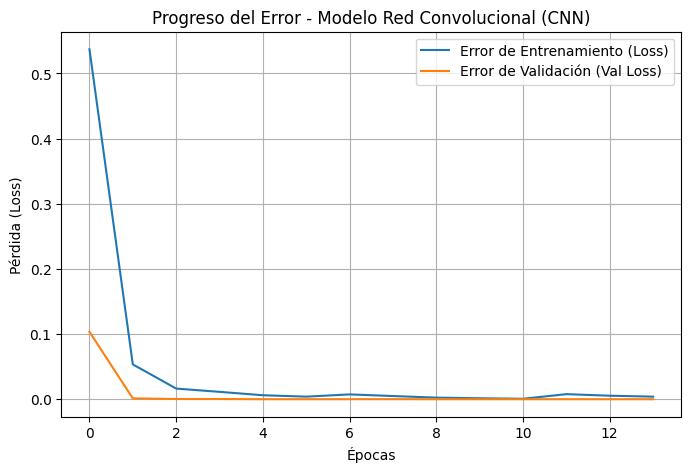

In [67]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Construcción de la arquitectura CNN 1D
modelo_cnn = Sequential([
    Conv1D(filters=32, kernel_size=5, activation='relu', input_shape=(2048, 1)),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=64, kernel_size=5, activation='relu'),
    MaxPooling1D(pool_size=2),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(4, activation='softmax')  # 4 clases de salida (Normal, Pista Interna, Elemento Rodante, Pista Externa)[cite: 27, 29]
])

# Compilación del modelo
modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early Stopping para evitar overfitting
early_stopping_cnn = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Entrenamiento
historial_cnn = modelo_cnn.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping_cnn]
)

# Gráfico del progreso del error (Loss)
plt.figure(figsize=(8, 5))
plt.plot(historial_cnn.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_cnn.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo Red Convolucional (CNN)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

In [68]:
import pandas as pd
from sklearn.metrics import classification_report

# Predicciones con la CNN
y_pred_probs_cnn = modelo_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

# Reporte en formato de tabla redondeado a 3 decimales
reporte_dict_cnn = classification_report(y_test, y_pred_cnn, target_names=clases_nombres, output_dict=True)
df_reporte_cnn = pd.DataFrame(reporte_dict_cnn).transpose().round(3)

print("\n--- Reporte de Clasificación (CNN) ---")
display(df_reporte_cnn)

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step

--- Reporte de Clasificación (CNN) ---


,precision,recall,f1-score,support
Normal,1.0,1.0,1.0,331.0
Pista Interna,1.0,1.0,1.0,94.0
Elemento Rodante,1.0,1.0,1.0,94.0
Pista Externa,1.0,1.0,1.0,94.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,613.0
weighted avg,1.0,1.0,1.0,613.0


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step


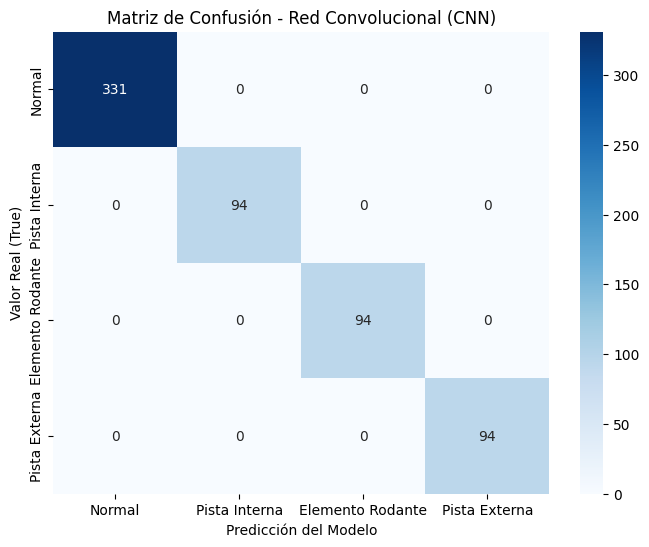

In [71]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Obtener las predicciones de la CNN
y_pred_probs_cnn = modelo_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

# 2. Calcular la matriz de confusión
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
clases_nombres = ['Normal', 'Pista Interna', 'Elemento Rodante', 'Pista Externa']

# 3. Graficar el mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases_nombres,
            yticklabels=clases_nombres)
plt.title('Matriz de Confusión - Red Convolucional (CNN)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (True)')
plt.show()

# ***ARQUITECTURA: Variante Profunda de MLP (Perceptrón Multicapa Profundo)***

In [69]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

# 1. Construcción de la arquitectura MLP modificada (más profunda)
modelo_mlp_v2 = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_norm.shape[1],)),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(4, activation='softmax')  # 4 clases de salida
])

# 2. Compilación del modelo
modelo_mlp_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Configuración de Early Stopping con mayor paciencia
early_stopping_v2 = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# 4. Entrenamiento
historial_mlp_v2 = modelo_mlp_v2.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping_v2]
)

# 5. Evaluación en el conjunto de Prueba (Test)
y_pred_probs_v2 = modelo_mlp_v2.predict(X_test_norm)
y_pred_v2 = np.argmax(y_pred_probs_v2, axis=1)

# 6. Reporte en formato de tabla redondeado a 3 decimales
reporte_dict_v2 = classification_report(y_test, y_pred_v2, target_names=clases_nombres, output_dict=True)
df_reporte_v2 = pd.DataFrame(reporte_dict_v2).transpose().round(3)

print("\n--- Reporte de Clasificación (MLP Variante Profunda) ---")
display(df_reporte_v2)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4883 - loss: 1.4411 - val_accuracy: 0.7108 - val_loss: 0.8735
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7464 - loss: 0.6702 - val_accuracy: 0.7882 - val_loss: 0.4889
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8122 - loss: 0.4343 - val_accuracy: 0.8045 - val_loss: 0.3902
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8679 - loss: 0.3407 - val_accuracy: 0.8473 - val_loss: 0.3225
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9082 - loss: 0.2448 - val_accuracy: 0.8350 - val_loss: 0.3499
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9337 - loss: 0.1811 - val_accuracy: 0.8839 - val_loss: 0.3451
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9480 - loss: 0.1499 - val_accuracy: 0.8717 - val_loss: 0.3471
Epoch 8/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9622 - loss: 0.1251 - val_accuracy: 0.8615 - val_loss: 0.

,precision,recall,f1-score,support
Normal,0.994,1.000,0.997,331.000
Pista Interna,0.681,0.500,0.577,94.000
Elemento Rodante,0.830,0.415,0.553,94.000
Pista Externa,0.524,0.915,0.667,94.000
accuracy,0.821,0.821,0.821,0.821
macro avg,0.757,0.707,0.698,613.000
weighted avg,0.849,0.821,0.814,613.000


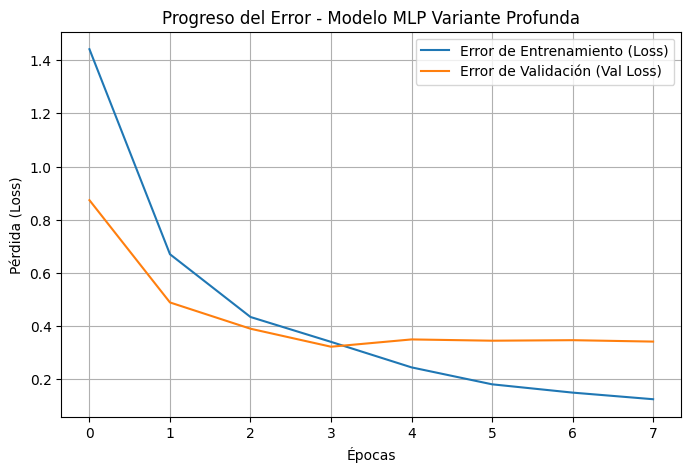

In [70]:
import matplotlib.pyplot as plt

# Gráfico del progreso del error (Loss) para la Variante Profunda del MLP
plt.figure(figsize=(8, 5))
plt.plot(historial_mlp_v2.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp_v2.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP Variante Profunda')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()